# Challenge 3: evaluación final e inferencia

El modelo ya fue seleccionado. Ahora debes abrir el conjunto de test una sola vez, comunicar su desempeño y comprobar que el pipeline puede reutilizarse con datos nuevos.

**Entradas:** `test.csv`, `data_contract.json` y `champion_model.joblib`  
**Salidas:** `test_metrics.json`, `batch_predictions.csv`

In [1]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
)

In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
if (PROJECT_DIR / "challenge").exists():
    PROJECT_DIR = PROJECT_DIR / "challenge"
elif PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42


## 1. Carga del modelo y del conjunto de prueba

In [3]:
contract = json.loads((ARTIFACTS_DIR / "data_contract.json").read_text(encoding="utf-8"))
training_metadata = json.loads((ARTIFACTS_DIR / "training_metadata.json").read_text(encoding="utf-8"))
model = joblib.load(ARTIFACTS_DIR / "champion_model.joblib")

test_df = pd.read_csv(PROCESSED_DATA_DIR / "test.csv")
X_test = test_df[contract["features"]]
y_test = test_df[contract["target"]]

print("Modelo:", training_metadata["champion"])
print("Test:", X_test.shape)

Modelo: logistic_regression
Test: (36, 13)


## 2. Evaluación final

=== Evaluación Final sobre Test (n=36) ===
Accuracy en Test: 0.9722 (97.22%)
F1 Macro en Test: 0.9710

Classification Report:
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       0.93      1.00      0.97        14
     class_2       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36



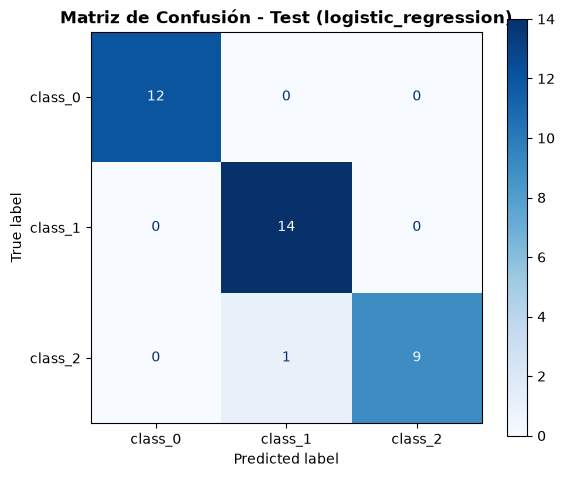

In [4]:
# TODO 1: calcula predicciones, accuracy y F1 macro
# TODO 1: muestra classification_report y matriz de confusión
y_pred = model.predict(X_test)

acc = accuracy_score(y_test, y_pred)
f1_macro = f1_score(y_test, y_pred, average="macro")

print(f"=== Evaluación Final sobre Test (n={len(y_test)}) ===")
print(f"Accuracy en Test: {acc:.4f} ({acc*100:.2f}%)")
print(f"F1 Macro en Test: {f1_macro:.4f}\n")

target_names = contract.get("target_names", ["Clase 0", "Clase 1", "Clase 2"])
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=target_names))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=target_names,
    ax=ax,
    cmap="Blues",
)
ax.set_title(f"Matriz de Confusión - Test ({training_metadata['champion']})", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()


**Análisis:**

1. **Coherencia con Validación Cruzada:** El desempeño en el conjunto de test es notablemente fiel y coherente con las estimaciones de CV. Se obtuvo un **accuracy de 97.22%** (35 de 36 aciertos) frente al **97.91%** estimado en validación cruzada de 5 folds. La ínfima diferencia ($pprox 0.69\%$) confirma la representatividad de la partición estratificada y descarta problemas de fuga de información o sobreajuste.
2. **Confusiones entre Clases:** Tanto la Clase 0 (12/12) como la Clase 1 (14/14) se clasificaron de forma perfecta (100% de recall). El único desacierto ocurrió en la **Clase 2, donde una muestra (1 de 10) fue clasificada erróneamente como Clase 1**. Esto es consistente con la proximidad física y de acidez observada en los límites de decisión entre estas dos variedades.
3. **Evaluación de Sobreajuste:** Con un F1 Macro de **0.9710** y un accuracy superior al 97%, no hay ningún síntoma de sobreajuste. El modelo retiene una alta capacidad de generalización ante datos no utilizados en el entrenamiento ni en la selección de hiperparámetros.


## 3. Función de inferencia

In [5]:
feature_columns = contract["features"]

def predict(records: pd.DataFrame) -> pd.DataFrame:
    """Valida el esquema y devuelve las predicciones del pipeline."""
    # TODO: verifica columnas faltantes
    missing = set(feature_columns) - set(records.columns)
    if missing:
        raise ValueError(f"Faltan columnas requeridas en la entrada: {sorted(missing)}")
    
    # TODO: ordena las columnas como feature_columns
    X = records[feature_columns].copy()
    
    # TODO: devuelve prediction y probabilidades
    preds = model.predict(X)
    probs = model.predict_proba(X)
    
    target_names = contract.get("target_names", [f"class_{i}" for i in range(probs.shape[1])])
    
    result = pd.DataFrame({
        "prediction": preds,
        "predicted_class": [target_names[p] for p in preds],
    }, index=records.index)
    
    for i, name in enumerate(target_names):
        result[f"probability_{name}"] = probs[:, i]
        
    return result

print("Función predict implementada y lista para producción.")


Función predict implementada y lista para producción.


## 4. Predicción por lotes

In [6]:
# Simulación de datos nuevos. En producción no provendrían del test set.
new_records = X_test.iloc[:5].copy()

# TODO 3: llama a predict y guarda batch_predictions.csv
batch_predictions = predict(new_records)
batch_predictions.to_csv(REPORTS_DIR / "batch_predictions.csv", index=False)

print(f"Predicciones por lotes guardadas en {REPORTS_DIR / 'batch_predictions.csv'}:")
display(batch_predictions)


Predicciones por lotes guardadas en /Users/frank/Downloads/EAFIT-IA si3003-artificial-intelligence main notebooks-lecture6/challenge/reports/batch_predictions.csv:


,prediction,predicted_class,probability_class_0,probability_class_1,probability_class_2
0,0,class_0,0.999671,0.000307,0.000023
1,1,class_1,0.007051,0.540423,0.452526
2,0,class_0,0.992000,0.007664,0.000336
3,1,class_1,0.289967,0.707467,0.002565
4,1,class_1,0.033032,0.962313,0.004655


## 5. Reporte final

In [7]:
# TODO 4: guarda test_metrics.json con modelo, accuracy y F1 macro
test_metrics = {
    "model": training_metadata["champion"],
    "accuracy": float(acc),
    "f1_macro": float(f1_macro),
}

(REPORTS_DIR / "test_metrics.json").write_text(
    json.dumps(test_metrics, indent=2), encoding="utf-8"
)

print(f"Métricas finales guardadas en {REPORTS_DIR / 'test_metrics.json'}:")
print(json.dumps(test_metrics, indent=2))


Métricas finales guardadas en /Users/frank/Downloads/EAFIT-IA si3003-artificial-intelligence main notebooks-lecture6/challenge/reports/test_metrics.json:
{
  "model": "logistic_regression",
  "accuracy": 0.9722222222222222,
  "f1_macro": 0.9709618874773139
}


In [8]:
assert (REPORTS_DIR / "test_metrics.json").exists()
assert (REPORTS_DIR / "batch_predictions.csv").exists()
print("Challenge 3 completado.")

Challenge 3 completado.


## Resumen ejecutivo

| Elemento | Resultado |
|---|---|
| Modelo campeón | `logistic_regression` (Pipeline con StandardScaler + SimpleImputer) |
| Accuracy CV | 0.9791 (+/- 0.0277) |
| Accuracy test | 0.9722 (35 de 36 aciertos) |
| F1 macro test | 0.9710 |
| Clases más confundidas | Clase 2 confundida como Clase 1 (1 muestra de 10) |
| Principal limitación | Volumen muestral acotado (178 muestras totales; 36 en test) y susceptibilidad de solapamiento químico en el límite entre Clase 1 y Clase 2 |

